# Exploring dataset
Dataset options
- text8 filtered wikipedia
- wikitext2 raw - can practice data filtering
- Fineweb / fineweb - edu
- project gutenberg - dumps of famous literature by authors
- common crawl 

First we will experiment with the smaller one text8
### What is text 8 ??
100MB of wikipedia data converted into lowercase characters and restricted to english alphabets


In [1]:
import torch
print(torch.backends.mps.is_available())

True


In [2]:
## Read the dataset
with open("../datasets/text8", "r") as f:
    text = f.read()
# text = text[:1000000]
print(text[:1000])

 anarchism originated as a term of abuse first used against early working class radicals including the diggers of the english revolution and the sans culottes of the french revolution whilst the term is still used in a pejorative way to describe any act that used violent means to destroy the organization of society it has also been taken up as a positive label by self defined anarchists the word anarchism is derived from the greek without archons ruler chief king anarchism as a political philosophy is the belief that rulers are unnecessary and should be abolished although there are differing interpretations of what this means anarchism also refers to related social movements that advocate the elimination of authoritarian institutions particularly the state the word anarchy as most anarchists use it does not imply chaos nihilism or anomie but rather a harmonious anti authoritarian society in place of what are regarded as authoritarian political structures and coercive economic instituti

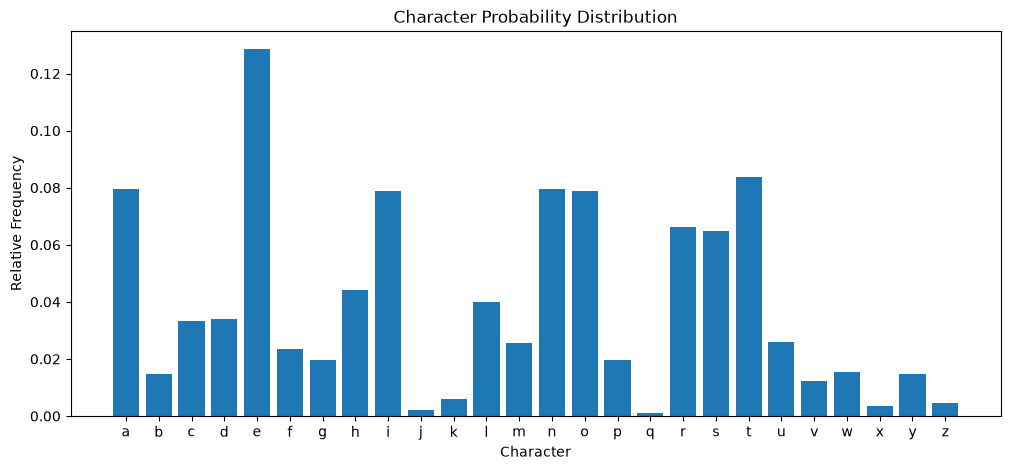

In [3]:
from collections import Counter
import string
import matplotlib.pyplot as plt

freq = Counter(c for c in text if c in string.ascii_lowercase)

letters = list(string.ascii_lowercase)
counts = [freq[c] for c in letters]

# Relative frequency
total = sum(counts)
probs = [count / total for count in counts]

plt.figure(figsize=(12, 5))
plt.bar(letters, probs)

plt.xlabel("Character")
plt.ylabel("Relative Frequency")
plt.title("Character Probability Distribution")
plt.show()

del freq,counts,letters,probs,total

In [4]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from collections import Counter

# For stop words removal
nltk.download('stopwords')

# For lemmatization (WordNetLemmatizer)
nltk.download('wordnet')
nltk.download('omw-1.4')  # Often required alongside wordnet in newer NLTK versions

# Stemmers (like Porter or Snowball) are built into the code, 
# but you usually need the tokenizer to split the text first:
nltk.download('punkt')

# create a lemmatizer instance
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

words = text.split()
print(f"Words prior to preprocessing: {len(words)}")

# 1. Count raw frequencies immediately
raw_counts = Counter(words)

# 2. Build translation map and calculate lemmatized frequencies
translation_map = {}
lemma_counts = {}

for word, count in raw_counts.items():
    if word not in stop_words:
        lemma = lemmatizer.lemmatize(word)
        translation_map[word] = lemma
        # Combine counts of words that lemmatize to the same root (e.g., jump + jumps)
        lemma_counts[lemma] = lemma_counts.get(lemma, 0) + count

# 3. Reconstruct corpus in text order, applying the frequency filter
# We only keep the word if it isn't a stopword AND its lemma appears > 4 times
processed_words = [
    translation_map[w] for w in words 
    if w in translation_map and lemma_counts[translation_map[w]] > 4
]

# 4. Final unique words
unique_words = Counter(processed_words)

print(f"Unique words after stopword & frequency filtering: {len(unique_words)}")
print(f"Remaining words in text order: {len(processed_words)}")
print(processed_words[:100])

for k,v in unique_words.items():
    print(k,' = ',v)
# Clean up memory
del raw_counts, translation_map, lemma_counts, lemmatizer, stop_words, words, text

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/d0lph1n/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/d0lph1n/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/d0lph1n/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /Users/d0lph1n/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Words prior to preprocessing: 17005207
Unique words after stopword & frequency filtering: 63661
Remaining words in text order: 10618707
['anarchism', 'originated', 'term', 'abuse', 'first', 'used', 'early', 'working', 'class', 'radical', 'including', 'digger', 'english', 'revolution', 'sans', 'culotte', 'french', 'revolution', 'whilst', 'term', 'still', 'used', 'pejorative', 'way', 'describe', 'act', 'used', 'violent', 'mean', 'destroy', 'organization', 'society', 'also', 'taken', 'positive', 'label', 'self', 'defined', 'anarchist', 'word', 'anarchism', 'derived', 'greek', 'without', 'archons', 'ruler', 'chief', 'king', 'anarchism', 'political', 'philosophy', 'belief', 'ruler', 'unnecessary', 'abolished', 'although', 'differing', 'interpretation', 'mean', 'anarchism', 'also', 'refers', 'related', 'social', 'movement', 'advocate', 'elimination', 'authoritarian', 'institution', 'particularly', 'state', 'word', 'anarchy', 'anarchist', 'use', 'imply', 'chaos', 'nihilism', 'anomie', 'rather

In [5]:
# processed_words = [] - sequential list of words after lemmtization, stemming and stop word removal

# make dataset object of two consecutive word pairs 

# write a simple word 2 vec with one hidden layer that takes one hto encoding as input and predicts the next word

# train that network

# perform pca and take some words with similar meaning and see thier repr in matplotlib

# plot the loss graph and other relevant graphs for this process






In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================
# 0. Setup MPS Device 
# ==========================================
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
device = torch.device("cuda" if torch.cuda.is_available() else device)
print(f"Training on device: {device}")

# ==========================================
# 1. Data & Preprocessing
# ==========================================
# Artificially expanding the dataset so batch_size=32 actually splits into multiple batches
# base_words = [
#     "king", "is", "strong", "man", 
#     "queen", "is", "wise", "woman",
#     "boy", "is", "young", "man",
#     "girl", "is", "young", "woman",
#     "prince", "is", "young", "king",
#     "princess", "is", "young", "queen"
# ]
# processed_words = base_words * 20  # Now we have enough data for multiple batches

vocab = list(set(processed_words))
vocab_size = len(vocab)
word2idx = {w: i for i, w in enumerate(vocab)}

# ==========================================
# 2. PyTorch Dataset & DataLoader
# ==========================================
class WordPairDataset(Dataset):
    def __init__(self, words, word2idx):
        # Pre-compute integer indices for speed
        self.pairs = [(word2idx[words[i]], word2idx[words[i+1]]) for i in range(len(words) - 1)]
        
    def __len__(self):
        return len(self.pairs)
        
    def __getitem__(self, idx):
        x, y = self.pairs[idx]
        return torch.tensor(x), torch.tensor(y)

# Instantiate the Dataset and DataLoader
dataset = WordPairDataset(processed_words, word2idx)
dataloader = DataLoader(dataset, batch_size=4096, shuffle=True)

print(f"Vocabulary Size: {vocab_size}")
print(f"Total training pairs: {len(dataset)}")
print(f"Batches per epoch: {len(dataloader)}")

# ==========================================
# 3. Model Definition
# ==========================================
class SimpleWord2Vec(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(SimpleWord2Vec, self).__init__()
        self.hidden_layer = nn.Linear(vocab_size, embedding_dim, bias=False)
        self.output_layer = nn.Linear(embedding_dim, vocab_size, bias=False)

    def forward(self, x):
        return self.output_layer(self.hidden_layer(x))

EMBEDDING_DIM = 10
EPOCHS = 100  # Reduced epochs since dataset is larger
LEARNING_RATE = 0.05

model = SimpleWord2Vec(vocab_size, EMBEDDING_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

# ==========================================
# 4. Batched Training Loop
# ==========================================
losses = []

print("Starting batched training...")
for epoch in range(EPOCHS):
    total_loss = 0.0
    
    for batch_idx, (x_batch, y_batch) in enumerate(dataloader):
        # Vectorized one-hot encoding on the batch, moved to MPS
        x_tensor = F.one_hot(x_batch, num_classes=vocab_size).float().to(device)
        y_tensor = y_batch.to(device)
        
        optimizer.zero_grad()
        predictions = model(x_tensor)
        
        loss = criterion(predictions, y_tensor)
        loss.backward()
        optimizer.step()
        
        # Track loss weighted by batch size to handle uneven final batches
        total_loss += loss.item() * x_tensor.size(0)
        
    avg_loss = total_loss / len(dataset)
    losses.append(avg_loss)
    
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.4f}")

# ==========================================
# 5. Extract Embeddings & Plot
# ==========================================
embeddings = model.hidden_layer.weight.data.t().cpu().numpy()

pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(losses, color='blue', linewidth=2)
ax1.set_title('Training Loss over Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Cross Entropy Loss')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], color='red', edgecolors='k')
ax2.set_title('Word Embeddings (PCA)')
ax2.set_xlabel('PC 1')
ax2.set_ylabel('PC 2')
ax2.grid(True, linestyle='--', alpha=0.6)

for i, word in enumerate(vocab):
    ax2.annotate(word, 
                 xy=(embeddings_2d[i, 0], embeddings_2d[i, 1]), 
                 xytext=(5, 2),
                 textcoords='offset points', 
                 ha='right', 
                 va='bottom',
                 fontsize=11)

plt.tight_layout()
plt.show()

Training on device: mps
Vocabulary Size: 63661
Total training pairs: 10618706
Batches per epoch: 2593
Starting batched training...


KeyboardInterrupt: 